# Clasificación de conversaciones con Machine Learning

## Desarrollo de modelos

Este cuaderno continúa el ciclo de Machine Learning:

1. Identificación de objetivos empresariales
2. Planteamiento del problema de ML
3. Procesamiento de datos
4. Desarrollo de modelos
5. Implementación
6. Supervisión
7. Reentrenamiento

En este cuaderno se cubren procesamiento básico, representación TF-IDF, comparación de modelos, validación cruzada estratificada y ajuste inicial.


## 1. Importación de librerías

In [22]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)
from sklearn.model_selection import StratifiedKFold, cross_validate


## 2. Carga del dataset

Coloca `CustomerInteractionData.csv` dentro de la carpeta `data/`.


In [23]:
df = pd.read_csv("../data/CustomerInteractionData.csv")

print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])

df.head()


Filas: 103
Columnas: 7


,RecordID,CustomerInteractionRawText,AgentAssignedTopic,LocationID,CallDurationSeconds,AgentID,CustomerID
0,1890041,Cus not satisfied with service. want to port o...,Port Out,8.0,10.0,z88Nr,5Ms7y
1,1890042,Jadav called to check his porting out status. ...,Port Out,1.0,6.0,xGAVI,s8Zyb
2,1890043,Customer thraetened to cancel her service. Sai...,Port Out,9.0,15.0,T7Kdd,3IB8J
3,1890044,called to ask steps for porting out. She is le...,Port Out,5.0,15.0,jtifd,mtR3W
4,1890045,Customer dissatisfied with support. Connectivi...,Port Out,7.0,13.0,hxY3d,DbBmN


## 3. Exploración inicial

In [24]:
print("Columnas:")
print(df.columns.tolist())

print("\nInformación:")
df.info()

print("\nValores nulos:")
print(df.isnull().sum())

print("\nDistribución de categorías:")
print(df["AgentAssignedTopic"].value_counts())


Columnas:
['RecordID', 'CustomerInteractionRawText', 'AgentAssignedTopic', 'LocationID', 'CallDurationSeconds', 'AgentID', 'CustomerID']

Información:
<class 'pandas.DataFrame'>
RangeIndex: 103 entries, 0 to 102
Data columns (total 7 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   RecordID                    103 non-null    int64  
 1   CustomerInteractionRawText  103 non-null    str    
 2   AgentAssignedTopic          103 non-null    str    
 3   LocationID                  100 non-null    float64
 4   CallDurationSeconds         102 non-null    float64
 5   AgentID                     102 non-null    str    
 6   CustomerID                  102 non-null    str    
dtypes: float64(2), int64(1), str(4)
memory usage: 5.8 KB

Valores nulos:
RecordID                      0
CustomerInteractionRawText    0
AgentAssignedTopic            0
LocationID                    3
CallDurationSeconds           1
AgentID  

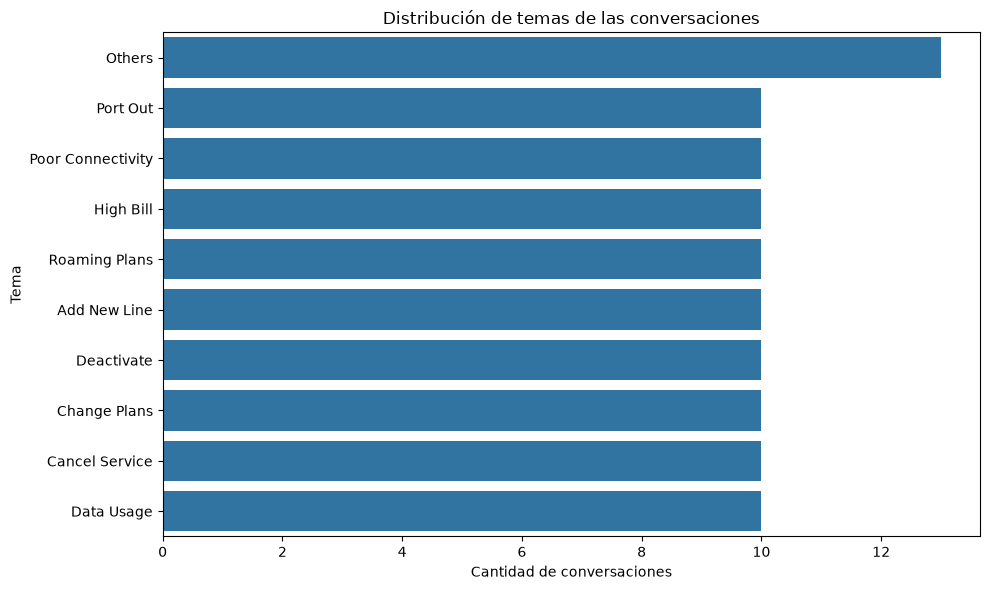

In [25]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    y="AgentAssignedTopic",
    order=df["AgentAssignedTopic"].value_counts().index
)

plt.title("Distribución de temas de las conversaciones")
plt.xlabel("Cantidad de conversaciones")
plt.ylabel("Tema")
plt.tight_layout()
plt.show()


## 4. Definición del problema de ML

**X** corresponde al texto de la conversación.

**y** corresponde al tema asignado por el agente.

Se trata de un problema de **clasificación supervisada multiclase de texto**.


In [26]:
X = df["CustomerInteractionRawText"].fillna("")
y = df["AgentAssignedTopic"]

print("X:", X.shape)
print("y:", y.shape)


X: (103,)
y: (103,)


## 5. División de entrenamiento y prueba

Se reserva el 20% para evaluación final. `stratify=y` conserva la proporción de las clases.


In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Entrenamiento:", len(X_train))
print("Prueba:", len(X_test))


Entrenamiento: 82
Prueba: 21


## 6. Modelo baseline: TF-IDF + Logistic Regression

In [28]:
vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2)
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Train:", X_train_tfidf.shape)
print("Test:", X_test_tfidf.shape)


Train: (82, 623)
Test: (21, 623)


In [29]:
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_tfidf, y_train)

y_pred = model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro")

print(f"Accuracy: {accuracy:.2%}")
print(f"Macro F1: {macro_f1:.4f}")

print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))


Accuracy: 71.43%
Macro F1: 0.6871

Classification report:
                   precision    recall  f1-score   support

     Add New Line       1.00      1.00      1.00         2
   Cancel Service       0.50      0.50      0.50         2
     Change Plans       0.50      1.00      0.67         2
       Data Usage       0.67      1.00      0.80         2
       Deactivate       0.00      0.00      0.00         2
        High Bill       1.00      1.00      1.00         2
           Others       0.50      0.67      0.57         3
Poor Connectivity       1.00      0.50      0.67         2
         Port Out       1.00      1.00      1.00         2
    Roaming Plans       1.00      0.50      0.67         2

         accuracy                           0.71        21
        macro avg       0.72      0.72      0.69        21
     weighted avg       0.71      0.71      0.68        21



## 7. Análisis de errores del baseline

In [30]:
resultados = pd.DataFrame({
    "texto": X_test.values,
    "real": y_test.values,
    "prediccion": y_pred
})

errores = resultados[resultados["real"] != resultados["prediccion"]]

print("Cantidad de errores:", len(errores))
errores.reset_index(drop=True)


Cantidad de errores: 6


,texto,real,prediccion
0,All India plans for Data usage. Don't want inc...,Roaming Plans,Data Usage
1,Customer terminated the offers permanently.,Deactivate,Change Plans
2,935468R911 called to report abrupt disconectio...,Poor Connectivity,Others
3,John Meyer want to cancel the current connection.,Cancel Service,Others
4,Decativated all plans due to change of user.,Deactivate,Change Plans
5,Customer wants to block calls from a particula...,Others,Cancel Service


In [31]:
for _, row in errores.iterrows():
    print("CONVERSACIÓN:")
    print(row["texto"])
    print("\nREAL:", row["real"])
    print("PREDICCIÓN:", row["prediccion"])
    print("=" * 80)


CONVERSACIÓN:
All India plans for Data usage. Don't want incoming call being charged.

REAL: Roaming Plans
PREDICCIÓN: Data Usage
CONVERSACIÓN:
Customer terminated the offers permanently.

REAL: Deactivate
PREDICCIÓN: Change Plans
CONVERSACIÓN:
935468R911 called to report abrupt disconection from network.

REAL: Poor Connectivity
PREDICCIÓN: Others
CONVERSACIÓN:
John Meyer want to cancel the current connection.

REAL: Cancel Service
PREDICCIÓN: Others
CONVERSACIÓN:
Decativated all plans due to change of user.

REAL: Deactivate
PREDICCIÓN: Change Plans
CONVERSACIÓN:
Customer wants to block calls from a particular number,

REAL: Others
PREDICCIÓN: Cancel Service


## 8. Comparación de modelos

Se mantiene la misma representación TF-IDF para comparar tres clasificadores.


In [32]:
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)
lr_model.fit(X_train_tfidf, y_train)
lr_pred = lr_model.predict(X_test_tfidf)

svm_model = LinearSVC(
    random_state=42
)
svm_model.fit(X_train_tfidf, y_train)
svm_pred = svm_model.predict(X_test_tfidf)

nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)
nb_pred = nb_model.predict(X_test_tfidf)

comparacion = pd.DataFrame({
    "Modelo": [
        "Logistic Regression",
        "Linear SVM",
        "Naive Bayes"
    ],
    "Accuracy": [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, svm_pred),
        accuracy_score(y_test, nb_pred)
    ],
    "Macro F1": [
        f1_score(y_test, lr_pred, average="macro"),
        f1_score(y_test, svm_pred, average="macro"),
        f1_score(y_test, nb_pred, average="macro")
    ]
})

comparacion.sort_values("Macro F1", ascending=False).reset_index(drop=True)


,Modelo,Accuracy,Macro F1
0,Logistic Regression,0.714286,0.687143
1,Linear SVM,0.714286,0.686667
2,Naive Bayes,0.619048,0.606667


## 9. Validación cruzada estratificada

La evaluación anterior depende de una única división train/test. Para reducir esa dependencia, utilizamos 5 particiones estratificadas.


In [33]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


In [34]:
pipeline_lr = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            stop_words="english",
            ngram_range=(1, 2)
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

scores_baseline = cross_validate(
    pipeline_lr,
    X_train,
    y_train,
    cv=cv,
    scoring=[
        "accuracy",
        "f1_macro",
        "precision_macro",
        "recall_macro"
    ]
)

print(f"Accuracy promedio: {scores_baseline['test_accuracy'].mean():.4f}")

print(f"Macro F1 promedio: {scores_baseline['test_f1_macro'].mean():.4f}")

print(f"Precision promedio: {scores_baseline['test_precision_macro'].mean():.4f}")

print(f"Recall promedio: {scores_baseline['test_recall_macro'].mean():.4f}")

print(f"Desviación Accuracy: {scores_baseline['test_accuracy'].std():.4f}")

print(f"Desviación Macro F1: {scores_baseline['test_f1_macro'].std():.4f}")

Accuracy promedio: 0.8037
Macro F1 promedio: 0.7694
Precision promedio: 0.8113
Recall promedio: 0.8000
Desviación Accuracy: 0.0498
Desviación Macro F1: 0.0710


c:\Users\Belen\OneDrive\Escritorio\proyectos\Clasificador de mensajes\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Belen\OneDrive\Escritorio\proyectos\Clasificador de mensajes\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Belen\OneDrive\Escritorio\proyectos\Clasificador de mensajes\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zer

## 10. Ajuste de la representación TF-IDF

Se prueban unigramas, bigramas y trigramas. Macro F1 será la métrica principal para seleccionar la configuración.


In [35]:
def evaluar_configuracion(ngram_range):
    pipeline = Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                lowercase=True,
                stop_words="english",
                ngram_range=ngram_range
            )
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=["accuracy", "f1_macro"]
    )

    return {
        "N-gram": str(ngram_range),
        "Accuracy": scores["test_accuracy"].mean(),
        "Macro F1": scores["test_f1_macro"].mean(),
        "Std Accuracy": scores["test_accuracy"].std(),
        "Std Macro F1": scores["test_f1_macro"].std()
    }


In [36]:
configuraciones = [
    (1, 1),
    (1, 2),
    (1, 3)
]

resultados_cv = pd.DataFrame([
    evaluar_configuracion(configuracion)
    for configuracion in configuraciones
])

resultados_cv = resultados_cv.sort_values(
    "Macro F1",
    ascending=False
).reset_index(drop=True)

resultados_cv


,N-gram,Accuracy,Macro F1,Std Accuracy,Std Macro F1
0,"(1, 1)",0.815441,0.774000,0.081429,0.110401
1,"(1, 2)",0.803676,0.769429,0.049848,0.070975
2,"(1, 3)",0.791912,0.756095,0.050709,0.064979


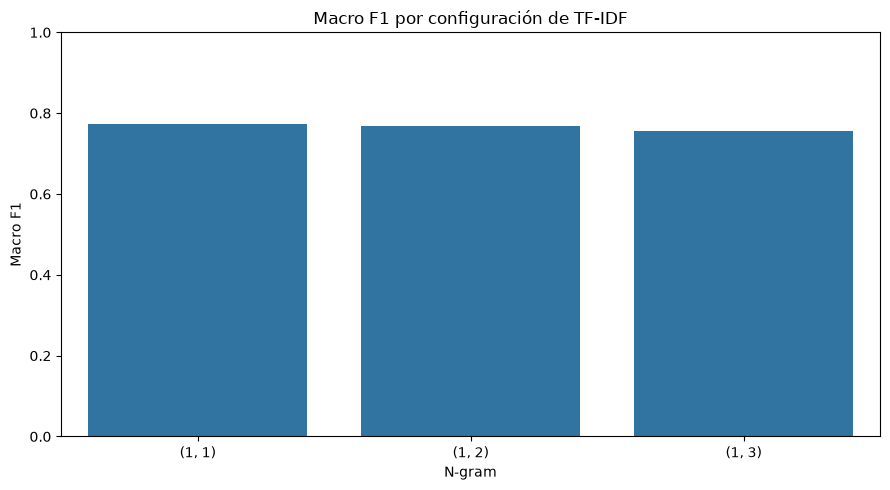

In [37]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=resultados_cv,
    x="N-gram",
    y="Macro F1"
)

plt.title("Macro F1 por configuración de TF-IDF")
plt.xlabel("N-gram")
plt.ylabel("Macro F1")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


## 11. Selección de la mejor configuración de TF-IDF

In [38]:
mejor_configuracion = resultados_cv.iloc[0]

print("Mejor configuración:")
print(mejor_configuracion)


Mejor configuración:
N-gram            (1, 1)
Accuracy        0.815441
Macro F1           0.774
Std Accuracy    0.081429
Std Macro F1    0.110401
Name: 0, dtype: object


## 12. Próximo ajuste: hiperparámetro C

Esta sección queda preparada para el siguiente experimento: evaluar distintos valores de `C` de Logistic Regression usando la mejor configuración de N-gramas encontrada anteriormente.


In [39]:
# Convertir la configuración seleccionada a una tupla real
mejor_ngram = tuple(map(int, mejor_ngram.strip("()").split(",")))

print("Mejor N-gram:", mejor_ngram)
print("Tipo:", type(mejor_ngram))

NameError: name 'mejor_ngram' is not defined

In [ ]:
valores_c = [0.1, 0.5, 1, 2, 5, 10]

resultados_c = []

for c in valores_c:
    pipeline = Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                lowercase=True,
                stop_words="english",
                ngram_range=mejor_ngram
            )
        ),
        (
            "classifier",
            LogisticRegression(
                C=c,
                max_iter=1000,
                random_state=42
            )
        )
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=[
            "accuracy",
            "f1_macro"
        ]
    )

    resultados_c.append({
        "C": c,
        "Accuracy": scores["test_accuracy"].mean(),
        "Macro F1": scores["test_f1_macro"].mean(),
        "Std Accuracy": scores["test_accuracy"].std(),
        "Std Macro F1": scores["test_f1_macro"].std()
    })

resultados_c = pd.DataFrame(resultados_c)

resultados_c = resultados_c.sort_values(
    "Macro F1",
    ascending=False
).reset_index(drop=True)

resultados_c

NameError: name 'mejor_ngram' is not defined

## 13. Criterio de selección

El modelo final de esta etapa se seleccionará priorizando **Macro F1**, y se revisarán también Accuracy y la variabilidad entre folds.

Después de seleccionar la configuración, el siguiente paso del ciclo será entrenar el modelo final y pasar a **implementación: inferencia y predicción**.


In [ ]:
modelo_final = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            stop_words="english",
            ngram_range=(1, 1)
        )
    ),
    (
        "classifier",
        LogisticRegression(
            C=1.0,
            max_iter=1000,
            random_state=42
        )
    )
])

modelo_final.fit(X_train, y_train)

print("Modelo final entrenado correctamente.")

Modelo final entrenado correctamente.


In [ ]:
pred_final = modelo_final.predict(X_test)

accuracy_final = accuracy_score(
    y_test,
    pred_final
)

macro_f1_final = f1_score(
    y_test,
    pred_final,
    average="macro"
)

print(f"Accuracy final: {accuracy_final:.2%}") #exactitud final
print(f"Macro F1 final: {macro_f1_final:.4f}")

Accuracy final: 66.67%
Macro F1 final: 0.6533


matriz de confusión

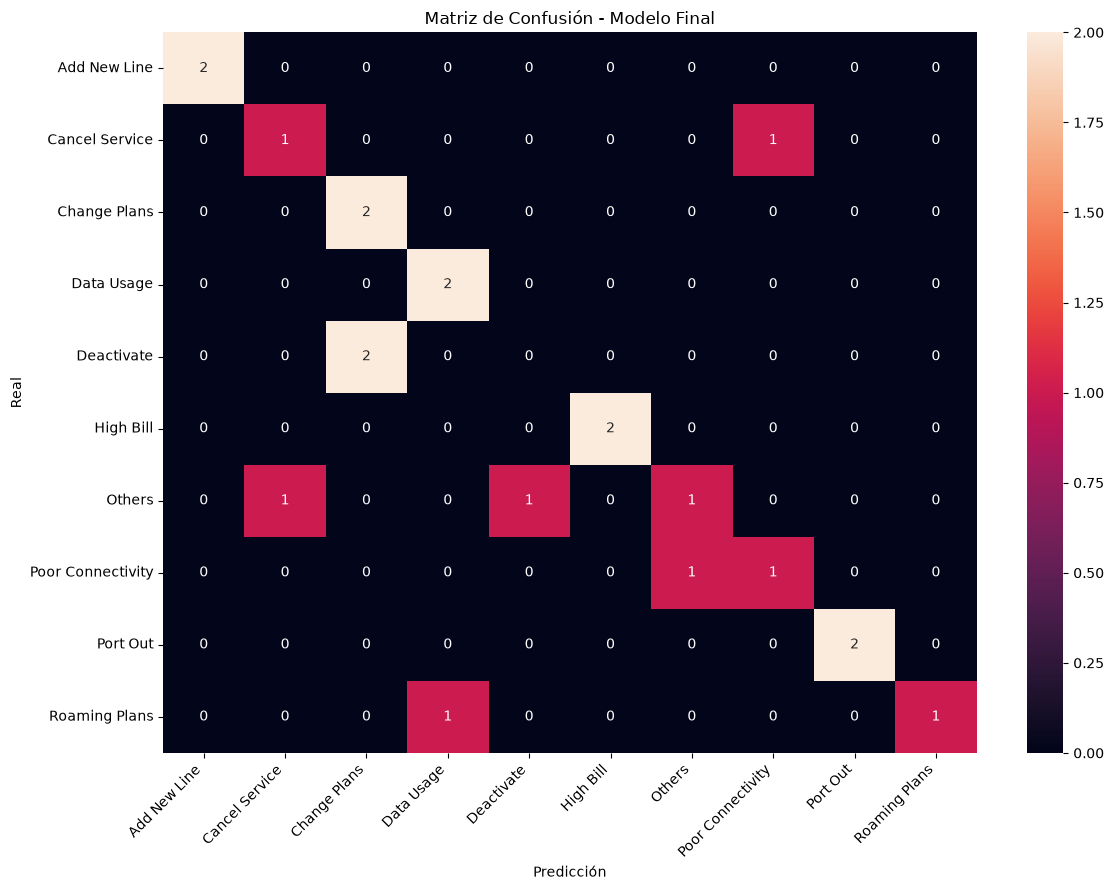

In [ ]:
cm = confusion_matrix(
    y_test,
    pred_final,
    labels=modelo_final.classes_
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=modelo_final.classes_,
    yticklabels=modelo_final.classes_
)

plt.title("Matriz de Confusión - Modelo Final")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
import joblib

joblib.dump(
    modelo_final,
    "modelo_clasificacion_conversaciones.joblib"
)

print("Modelo guardado correctamente.")

Modelo guardado correctamente.


In [40]:
cv_reentrenamiento = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [ ]:
pipeline_base_cv = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            stop_words="english",
            ngram_range=(1, 1)
        )
    ),
    (
        "classifier",
        LogisticRegression(
            C=1.0,
            max_iter=1000,
            random_state=42
        )
    )
])

scores_base_cv = cross_validate(
    pipeline_base_cv,
    X_train,
    y_train,
    cv=cv_reentrenamiento,
    scoring=[
        "accuracy",
        "f1_macro"
    ]
)

print(
    f"Accuracy promedio base: "
    f"{scores_base_cv['test_accuracy'].mean():.4f}"
)

print(
    f"Macro F1 promedio base: "
    f"{scores_base_cv['test_f1_macro'].mean():.4f}"
)